Copyright (c) 2026 Prefeitura Municipal de São José do Norte, RS.

This program is free software: you can redistribute it and/or modify it under
the terms of the GNU Affero General Public License as published by the Free
Software Foundation, either version 3 of the License, or (at your option) any
later version. See the LICENSE file for details.

# LDO 2027: Metodologia e memória de cálculo

## 1. Introdução

O presente documento visa detalhar a metodologia de cálculo empregada na previsão de receitas para a Lei de Diretrizes Orçamentárias (LDO).

In [1]:
from pandas import read_csv, concat, DataFrame, Index, to_datetime, Series, Timestamp
from bcb import Expectativas, sgs 
from bcb.odata.api import Endpoint 
from statsmodels.formula.api import ols 
from statsmodels.regression.linear_model import OLS, RegressionResultsWrapper, RegressionResults
from numpy import log, exp, round 
from matplotlib.pyplot import scatter, plot, fill_between, show 
from typing import Callable
from regex import sub
from os import path

O horizonte da previsão é de $4$ anos: de $t + 1$ até $t + 4$, para $t = 2026$

In [2]:
FIRST_FC_YEAR: int = 2027
FC_STEPS: int = 4
FC_RANGE: range = range(FIRST_FC_YEAR, FIRST_FC_YEAR + FC_STEPS)

FC_RANGE

range(2027, 2031)

## 2. Dados

Para a realização das previsões, serão usados, além dos dados de receita propriamente ditos, também dados relativos à inflação (IPCA), à taxa de juros (SELIC), ao Índice de Participação dos Municípios (IPM). Também serão criadas algumas variáveis *dummy*, conforme passará a ser feito em tempo oportuno.

### 2.1 Receitas

Os dados brutos de receita são obtidos da API de Dados Abertos do Tribunal de Contas do Estado do Rio Grande do Sul (TCE/RS). Os dados têm frequência anual e será usada a série histórica compreendida entre o ano de 2014 e o presente ano, 2026.

In [3]:
def fetch_revenues(period: range, file_path: str, overwrite: bool = False) -> None:
    if path.exists(file_path) & (not overwrite):
        print(
            '''
            O arquivo já está baixado. Se você baixar, provavelmente estará atualizando
            \nos dados e os resultados serão diferentes.
            \n Se você deseja sobrescrever os dados assim mesmo, use overwrite=True
            '''
        )
    else:
        URL : str = 'https://dados.tce.rs.gov.br/dados/municipal/balancete-receita/%s/58500.csv'
        concat([read_csv(URL %ano) for ano in PERIOD]).to_csv(file_path, index=False)


In [4]:
PERIOD: range = range(2014,2027)
fetch_revenues(PERIOD, 'data/revenues.csv')


            O arquivo já está baixado. Se você baixar, provavelmente estará atualizando
            
os dados e os resultados serão diferentes.
            
 Se você deseja sobrescrever os dados assim mesmo, use overwrite=True
            


In [5]:
raw_revenues_schema: dict[str, str] = {
    'ANO': int,
    'CD_CONTA_SG': str,
    'DS_CONTA_SG': str,
    'NIVEL': str,
    'VL_ORCADO': float,
    'VL_ARRECADADO': float,
    'MES': int,
}

raw_revenues: DataFrame = read_csv('data/revenues.csv')

raw_revenues

,ANO,BIMESTRE,COD_MUNICIPIO,NOME_MUNICIPIO,CD_ORGAO,NOME_ORGAO,CD_RECEBIMENTO,CD_ORGAO_ORCAMENTARIO,NOME_ORGAO_ORCAMENTARIO,CD_UNIDADE_ORCAMENTARIA,...,NR_NIVEL,CD_RECURSO,NM_RECURSO,CAR_PECULIAR,DS_CAR_PECULIAR,VL_ORCADO,VL_ARRECADADO,MES,CD_FONTE_RECURSO,CD_ACOMP_EXEC_ORC
0,2014,6.0,185,SÃO JOSÉ DO NORTE,58500,PM DE SÃO JOSÉ DO NORTE,128553,0,NaN,0,...,1,NaN,NaN,0,Não se Aplica,56013965.0,62641519.99,NaN,NaN,NaN
1,2014,6.0,185,SÃO JOSÉ DO NORTE,58500,PM DE SÃO JOSÉ DO NORTE,128553,0,NaN,0,...,2,NaN,NaN,0,Não se Aplica,4277500.0,11381466.86,NaN,NaN,NaN
2,2014,6.0,185,SÃO JOSÉ DO NORTE,58500,PM DE SÃO JOSÉ DO NORTE,128553,0,NaN,0,...,3,NaN,NaN,0,Não se Aplica,4020000.0,11117812.91,NaN,NaN,NaN
3,2014,6.0,185,SÃO JOSÉ DO NORTE,58500,PM DE SÃO JOSÉ DO NORTE,128553,0,NaN,0,...,4,NaN,NaN,0,Não se Aplica,1520000.0,2253512.48,NaN,NaN,NaN
4,2014,6.0,185,SÃO JOSÉ DO NORTE,58500,PM DE SÃO JOSÉ DO NORTE,128553,0,NaN,0,...,5,NaN,NaN,0,Não se Aplica,680000.0,1508837.22,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7197,2026,NaN,185,SÃO JOSÉ DO NORTE,58500,PM DE SÃO JOSÉ DO NORTE,392435,0,NaN,0,...,5,0.0,NaN,0,Não se Aplica,4622600.0,64703.30,8.0,0.0,0.0
7198,2026,NaN,185,SÃO JOSÉ DO NORTE,58500,PM DE SÃO JOSÉ DO NORTE,392435,0,NaN,0,...,7,0.0,NaN,0,Não se Aplica,4622600.0,64703.30,8.0,0.0,0.0
7199,2026,NaN,185,SÃO JOSÉ DO NORTE,58500,PM DE SÃO JOSÉ DO NORTE,392435,0,NaN,0,...,8,0.0,NaN,0,Não se Aplica,4622600.0,64703.30,8.0,0.0,0.0
7200,2026,NaN,185,SÃO JOSÉ DO NORTE,58500,PM DE SÃO JOSÉ DO NORTE,392435,4,SEC. MUNIC. DA FAZENDA,1,...,9,0.0,NaN,0,Não se Aplica,4297500.0,0.00,8.0,1701.0,0.0


Como os dados do ano corrente são parciais, será projetada a arredação final para o ano, através de uma média composta pela simulação da arrecadação pela média mensal observada e pelo valor orçado.

In [6]:
def project_december(column: Series) -> float:
    period = column.fillna(12)['MES']
    if period < 12:
        return (column['VL_ORCADO'] + column['VL_ARRECADADO']*12/period)/2
    else:
        return column['VL_ARRECADADO']

revenues: DataFrame = raw_revenues.copy()

revenues['VL_PROJETADO'] = revenues.apply(project_december, axis=1)

Além disso, como a única intenção é a previsão da receita corrente, é realizada a filtragem de todas as outras categorias econômicas.

In [7]:
revenues['CD_CONTA_SG'] = revenues['CD_CONTA_SG'].astype('str')
revenues = revenues.loc[revenues['CD_CONTA_SG'].str.startswith('1')]

Uma vez que será usado o método de previsão hierárquica, serão obtidos os dados sintéticos dos grupos de origem da receita corrente (1.1, 1.2, etc.).

In [8]:
groups_dict: dict[str, dict[str, str]] = {
    '11' : {'cod': '11000000000000000000', 'desc': 'impostos', 'name': 'Impostos, Taxas e Contribuicoes de Melhoria'},
    '12' : {'cod': '12000000000000000000', 'desc': 'contribuicoes', 'name' : 'Contribuicoes'},
    '13' : {'cod': '13000000000000000000', 'desc': 'patrimonial', 'name' : 'Receita Patrimonial'},
    '16' : {'cod': '16000000000000000000', 'desc': 'servicos', 'name' : 'Receita de Servicos'},
    '17' : {'cod': '17000000000000000000', 'desc': 'transferencias', 'name' : 'Transferencias Correntes'},
    '19' : {'cod': '19000000000000000000', 'desc': 'outras', 'name' : 'Outras Receitas Correntes'}
}

Destes grupos, serão separadas para estimação própria as receitas cuja hipótese de *ceteris paribus* é sabidamente não plausível, bem como as receitas cuja hipótese de pesos estáveis dentro de seu grupo também não é assumível. A saber, trata-se da "Taxa de Limpeza Pública" e das cota-partes do "Fundo de Participação dos Municípios (FPM)" e do "Imposto Sobre Circulação de Mercadorias e Serviços (ICMS)".

In [9]:
exceptions_dict = {
    
    '11229000000000000000' : {'cod': '11225300000000000000', 'desc': 'limpeza_publica', 'name' : 'Taxa de limpeza pública'},
    '11220111020000000000' : {'cod': '11225300000000000000', 'desc': 'limpeza_publica', 'name' : 'Taxa de limpeza pública'},
    '11280291020000000000' : {'cod': '11225300000000000000', 'desc': 'limpeza_publica', 'name' : 'Taxa de limpeza pública'},
    '11220101020000000000' : {'cod': '11225300000000000000', 'desc': 'limpeza_publica', 'name' : 'Taxa de limpeza pública'},
    '11225300000000000000' : {'cod': '11225300000000000000', 'desc': 'limpeza_publica', 'name' : 'Taxa de limpeza pública'},
    
    
    '17210102000000000000' : {'cod': '17115100000000000000', 'desc': 'fpm', 'name' : 'FPM'},
    '17180120000000000000' : {'cod': '17115100000000000000', 'desc': 'fpm', 'name' : 'FPM'},
    '17115100000000000000' : {'cod': '17115100000000000000', 'desc': 'fpm', 'name' : 'FPM'},
    
    '17220101000000000000' : {'cod': '17215000000000000000', 'desc': 'icms', 'name' : 'ICMS'},
    '17280110000000000000' : {'cod': '17215000000000000000', 'desc': 'icms', 'name' : 'ICMS'},
    '17215000000000000000' : {'cod': '17215000000000000000', 'desc': 'icms', 'name' : 'ICMS'},
    
}

Outra necessidade é remover as contas redutoras, referentes à deduções, tendo em vista que as receitas devem ser previstas na sua forma bruta.

In [10]:
revenues = revenues.loc[
    (revenues['VL_ORCADO'] > 0)
    & (
        (revenues['NIVEL'] == 'A')
        | (revenues['CD_CONTA_SG'].isin(exceptions_dict.keys()))
    )
]

Os grupos sintéticos quanto à origem terão seus nomes e códigos normalizados conforme o dicionário e, então, é realizado o pivotamento dos dados, obtendo por resultado um dataset onde cada coluna é uma receita e cada índice é um ano.

In [11]:
def normalize_revenues(
        row: Series, 
        what: str, 
        groups: dict[str, dict[str, str]] = groups_dict, 
        exceptions: dict[str, dict[str, str]] = exceptions_dict
    ) -> str:
    cod: str = row['CD_CONTA_SG']
    desc: str = row['DS_CONTA_SG']
    current: dict[str, str] = {'cod': cod, 'desc': desc}
    result: dict[str, str] = exceptions.get(
        cod , 
        groups.get(
            str(cod)[:2], 
            current
        )
    )
    return result[what]

In [ ]:
revenues['DS_NORM'] = revenues.apply(lambda row : normalize_revenues(row, 'desc'), axis=1)
revenues['CD_NORM'] = revenues.apply(lambda row : normalize_revenues(row, 'cod'), axis=1)

In [13]:
revenues: DataFrame = revenues.pivot_table(
    index='ANO',
    columns='DS_NORM',
    values='VL_PROJETADO',
    aggfunc='sum'
)

revenues

DS_NORM,contribuicoes,fpm,icms,impostos,limpeza_publica,outras,patrimonial,servicos,transferencias
ANO,,,,,,,,,
2014,4.782632e+05,15378249.11,8.690351e+06,11365988.24,15135.08,1308161.160,1.083170e+06,365744.26,4.771740e+07
2015,4.509709e+05,15649870.57,8.874501e+06,9157650.24,12182.04,1967812.200,1.131144e+06,212842.67,5.133415e+07
2016,3.759319e+05,15970178.65,9.493333e+06,7550722.48,12562.24,3135702.490,1.101560e+06,603263.34,5.991614e+07
2017,5.701709e+05,17120249.91,1.030070e+07,6333522.84,10803.20,2486075.130,6.726201e+05,187575.03,6.189224e+07
2018,4.111386e+05,17297836.30,1.168442e+07,7501126.35,8585.24,554010.880,4.565817e+05,209182.13,6.357749e+07
2019,7.276591e+05,18753309.22,1.204554e+07,8555076.10,11160.09,639295.000,2.961936e+05,45006.26,6.649145e+07
2020,6.272542e+05,17859971.95,2.508008e+07,8700972.19,12164.60,775712.110,1.879635e+05,40936.45,8.509722e+07
2021,7.644329e+05,24079985.16,3.363498e+07,12067527.24,18370.97,789263.440,7.256433e+05,30778.40,1.000629e+08
2022,7.727091e+05,29979873.64,1.490192e+07,8960486.20,538738.85,738335.800,3.035846e+06,37593.91,9.208552e+07


As receitas de exceção aos seus grupos são deduzidas de seus grupos originários para evitar dupla-contagem.

In [14]:
revenues['impostos'] -= revenues['limpeza_publica']
revenues['transferencias'] -= revenues['fpm'] + revenues['icms']

In [15]:
revenues

DS_NORM,contribuicoes,fpm,icms,impostos,limpeza_publica,outras,patrimonial,servicos,transferencias
ANO,,,,,,,,,
2014,4.782632e+05,15378249.11,8.690351e+06,11350853.16,15135.08,1308161.160,1.083170e+06,365744.26,2.364880e+07
2015,4.509709e+05,15649870.57,8.874501e+06,9145468.20,12182.04,1967812.200,1.131144e+06,212842.67,2.680978e+07
2016,3.759319e+05,15970178.65,9.493333e+06,7538160.24,12562.24,3135702.490,1.101560e+06,603263.34,3.445262e+07
2017,5.701709e+05,17120249.91,1.030070e+07,6322719.64,10803.20,2486075.130,6.726201e+05,187575.03,3.447129e+07
2018,4.111386e+05,17297836.30,1.168442e+07,7492541.11,8585.24,554010.880,4.565817e+05,209182.13,3.459524e+07
2019,7.276591e+05,18753309.22,1.204554e+07,8543916.01,11160.09,639295.000,2.961936e+05,45006.26,3.569260e+07
2020,6.272542e+05,17859971.95,2.508008e+07,8688807.59,12164.60,775712.110,1.879635e+05,40936.45,4.215717e+07
2021,7.644329e+05,24079985.16,3.363498e+07,12049156.27,18370.97,789263.440,7.256433e+05,30778.40,4.234795e+07
2022,7.727091e+05,29979873.64,1.490192e+07,8421747.35,538738.85,738335.800,3.035846e+06,37593.91,4.720373e+07


### 2.2 Preços

Para representar o nível de preços, será usado o Índice nacional de Preços ao Consumidor Amplo (IPCA). Além dos valores observados, a série também será compostas das expectativas do indicador, conforme abaixo demonstrado.

#### 2.2.1 Preços observados

A série dos valores observados do IPCA são obtidos pela série 433 do Sistema Gerador de Séries Temporais (SGS) do Banco Central do Brasil. Eles estão em frequência mensal e correspondem ao período de $2014% até o último mês divulgado: setembro de 2026.

In [16]:
# Extract: observed values
ipca_obs : DataFrame = sgs.get(('Media', 433), start='2014-01-01', end='2026-09-30')\
                          .reset_index() \
                          .rename(columns={'Date': 'DataReferencia'})
                         

ipca_obs

,DataReferencia,Media
0,2014-01-01,0.55
1,2014-02-01,0.69
2,2014-03-01,0.92
3,2014-04-01,0.67
4,2014-05-01,0.46
...,...,...
148,2026-05-01,0.58
149,2026-06-01,0.16
150,2026-07-01,0.07
151,2026-08-01,-0.32


#### 2.2.2 Preços esperados (previsão mensal)

Já os valores esperados para o futuro são obtidos do sistema Focus de Expectativas de Mercado, também do Banco Central.

In [17]:
ep_ipca_mon: Endpoint = Expectativas().get_endpoint('ExpectativaMercadoMensais')

Mais precisamente, está sendo usado o último relatório divulgado no momento: referente a 16/10/2026.

In [18]:
last_report: Timestamp = ep_ipca_mon.query().select(ep_ipca_mon.Data).limit(1).collect()['Data'].item()

last_report

Timestamp('2026-10-16 00:00:00')

In [19]:
# Valor hardcoded para evitar atualização não intencional
REF_DATE: str = '2026-10-16'

Será usada a média das expectativas.

In [ ]:
# Extract: expected values
raw_ipca_exp_mon: DataFrame = ep_ipca_mon.query() \
                                         .filter(
                                             ep_ipca_mon.Indicador == 'IPCA',
                                             ep_ipca_mon.Data == REF_DATE,
                                             ep_ipca_mon.baseCalculo == '1'
                                          ) \
                                         .select(
                                             ep_ipca_mon.DataReferencia,
                                             ep_ipca_mon.Media
                                          ) \
                                         .collect()

In [21]:
ipca_exp_mon: DataFrame = raw_ipca_exp_mon.copy()
ipca_exp_mon['DataReferencia'] = to_datetime(ipca_exp_mon.DataReferencia, format='%m/%Y')
ipca_exp_mon = ipca_exp_mon.loc[ipca_exp_mon.DataReferencia > ipca_obs.DataReferencia.max()]
ipca_exp_mon.sort_values(by='DataReferencia', inplace=True)

ipca_exp_mon

/tmp/ipykernel_1803317/3372604644.py:4: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  ipca_exp_mon.sort_values(by='DataReferencia', inplace=True)


,DataReferencia,Media
24,2026-10-01,0.3187
23,2026-11-01,0.3105
22,2026-12-01,0.5719
21,2027-01-01,0.4863
20,2027-02-01,0.6711
19,2027-03-01,0.4458
18,2027-04-01,0.4301
17,2027-05-01,0.3157
16,2027-06-01,0.2195
15,2027-07-01,0.2169


#### 2.2.3 Preços esperados (previsão anual)

Como as expectativas de maior frequência (mensal) não estão disponíveis por todo o horizonte de previsão desejado, se usa as expectativas anuais do mesmo relatório.

In [22]:
ep_ipca_year: Endpoint = Expectativas().get_endpoint('ExpectativasMercadoAnuais')

In [ ]:
# Extract
raw_ipca_exp_year: DataFrame = ep_ipca_year.query() \
                                           .filter(
                                               ep_ipca_year.Indicador == 'IPCA',
                                               ep_ipca_year.Data == REF_DATE,
                                               ep_ipca_year.baseCalculo == '1'
                                            ) \
                                            .select(
                                                ep_ipca_year.DataReferencia,
                                                ep_ipca_year.Media
                                            ) \
                                            .collect()

Para mensalizar as expectativas anuais, é obtida a média geométrica mensal, por tratar-se de série multiplicativa.

In [24]:
ipca_exp_year: DataFrame = raw_ipca_exp_year.copy()

ipca_exp_year['Media'] **= 1/12
ipca_exp_year['Media'] -= 1

In [25]:
ipca_exp_year['DataReferencia'] = to_datetime(ipca_exp_year.DataReferencia, format='%Y')
ipca_exp_year = ipca_exp_year.set_index('DataReferencia').resample('MS').first().ffill().reset_index()
ipca_exp_year = ipca_exp_year[ipca_exp_year.DataReferencia > ipca_exp_mon.DataReferencia.max()]

ipca_exp_year

,DataReferencia,Media
34,2028-11-01,0.117517
35,2028-12-01,0.117517
36,2029-01-01,0.115294
37,2029-02-01,0.115294
38,2029-03-01,0.115294
39,2029-04-01,0.115294
40,2029-05-01,0.115294
41,2029-06-01,0.115294
42,2029-07-01,0.115294
43,2029-08-01,0.115294


#### 2.2.4  Merge

Por fim, é realizada a mescla de toda a série de IPCA.

In [ ]:
ipca: DataFrame = concat([ipca_obs, ipca_exp_mon, ipca_exp_year]).sort_values(by='DataReferencia')
ipca.columns = ['Date', 'ipca']

É tomado o produto acumulado da série.

In [27]:
ipca['ipca'] = (ipca.ipca/100 + 1).cumprod()
ipca = ipca.reset_index(drop=True)

E a série é anualizada.

In [28]:
ipca = ipca.set_index('Date').resample('YE').last().reset_index()
ipca['ipca'] = ipca['ipca'] / ipca['ipca'].min()
ipca['Date'] = ipca['Date'].dt.year

ipca 

,Date,ipca
0,2014,1.000000
1,2015,1.106735
2,2016,1.176327
3,2017,1.210998
4,2018,1.256355
5,2019,1.310454
6,2020,1.369652
7,2021,1.507454
8,2022,1.594657
9,2023,1.668348


### 2.3 Juros

#### 2.3.1 Juros observados

Quanto aos juros, a série observada aproveitada refere-se ao período entre 2014 e o último ano: 2025.

In [29]:
LAST_YEAR: int = FIRST_FC_YEAR - 2

LAST_YEAR

2025

Os dados são provenientes da série 4390 do SGS do Banco Central, e têm a frequência bruta mensal.

In [30]:
# Extract: observed values
raw_selic_obs : DataFrame = DataFrame(sgs.get(('selic', 4390), start='2014-01-01', end=f'{LAST_YEAR}-12-31'))

raw_selic_obs

,selic
Date,
2014-01-01,0.85
2014-02-01,0.79
2014-03-01,0.77
2014-04-01,0.82
2014-05-01,0.87
...,...
2025-08-01,1.16
2025-09-01,1.22
2025-10-01,1.28


É tomado o produto acumulado da série.

In [31]:
selic_obs = raw_selic_obs.copy()

selic_obs['selic'] = (selic_obs['selic'].div(100) + 1).groupby(selic_obs.index.year).cumprod()

selic_obs

,selic
Date,
2014-01-01,1.008500
2014-02-01,1.016467
2014-03-01,1.024294
2014-04-01,1.032693
2014-05-01,1.041678
...,...
2025-08-01,1.090380
2025-09-01,1.103683
2025-10-01,1.117810


E, então, anualizada.

In [32]:
selic_obs = selic_obs.resample('YE').last()

# Transform: index
selic_obs = selic_obs.reset_index()
selic_obs['Date'] = selic_obs.Date.dt.year.astype(int)

selic_obs

,Date,selic
0,2014,1.109101
1,2015,1.132858
2,2016,1.140284
3,2017,1.099556
4,2018,1.064215
5,2019,1.059459
6,2020,1.027538
7,2021,1.044357
8,2022,1.123805
9,2023,1.130282


#### 2.3.2 Juros esperados

Já as taxas de juros esperadas são provenientes do [Relatório Focus de Mercado, do Banco Central, na edição de 16/10/2023](https://www.bcb.gov.br/content/focus/focus/R20261016.pdf). Os dados já estão em acumulados anuais.

É tomado por hipótese que o ano de 2030 terá a mesma expectativa do que a do ano de 2029.

In [33]:
selic_expec: DataFrame = DataFrame({
    'Date': [2026, 2027, 2028, 2029, 2030],
    'selic' : [1.1325, 1.12, 1.105, 1.1, 1.1]
})

selic_expec

,Date,selic
0,2026,1.1325
1,2027,1.1200
2,2028,1.1050
3,2029,1.1000
4,2030,1.1000


#### 2.3.3 Merge

Obtidos os valores observados e experados, é feita a mesclagem.

In [34]:
selic: DataFrame = concat([selic_obs, selic_expec])

E é tomado o produto acumulado da série.

In [35]:
# Transform: concatening data
selic['selic'] = selic['selic'].cumprod()
selic['selic'] /= selic.loc[selic['Date'] == selic['Date'].min(), 'selic'].item()

selic

,Date,selic
0,2014,1.000000
1,2015,1.132858
2,2016,1.291780
3,2017,1.420384
4,2018,1.511595
5,2019,1.601473
6,2020,1.645575
7,2021,1.718567
8,2022,1.931334
9,2023,2.182953


### 2.4 IPM

#### 2.4.1 IPM Observado

Os valores de IPM observados são obtidos da SEFAZ/RS e têm a frequência anual. Enquanto para os períodos $\leq t$ os valores correspondem ao índice definitivo, o valor correspondente a $t + 1$ corresponde ao índice provisório.

In [36]:
# Extract
raw_ipm_obs: DataFrame = read_csv('data/ipm.csv') \
                            .astype({'index': 'datetime64[ns]', 'ipm': 'float'}) \
                            .rename(columns={'index': 'data'})

raw_ipm_obs

,data,ipm
0,2014-01-01,0.134713
1,2015-01-01,0.130225
2,2016-01-01,0.125974
3,2017-01-01,0.130259
4,2018-01-01,0.135589
5,2019-01-01,0.136289
6,2020-01-01,0.278565
7,2021-01-01,0.286067
8,2022-01-01,0.140493
9,2023-01-01,0.238248


In [37]:
ipm_obs: DataFrame = raw_ipm_obs.copy()

ipm_obs['data'] = ipm_obs['data'].dt.year

ipm_obs

,data,ipm
0,2014,0.134713
1,2015,0.130225
2,2016,0.125974
3,2017,0.130259
4,2018,0.135589
5,2019,0.136289
6,2020,0.278565
7,2021,0.286067
8,2022,0.140493
9,2023,0.238248


#### 2.4.2  IPM Projetado

Uma vez que a série histórica conta com *outliers* decorrentes dos efeitos das atividades do Estaleiro Brasil (EBR) e também do deferimento das CVIs, a projeção consiste em calcular a tendência média de evolução da série através da média geométrica entre o valor mais recente e o mais antigo sem tais *outliers* e, então, projetá-los para o horizonte de previsão.

In [ ]:
def project_ipm(
        df: DataFrame, 
        first_no_outlier_year: int, 
        last_no_outlier_year: int, 
        steps: int, 
        first_projected_year: int) -> DataFrame:
    series: DataFrame = df.set_index('data')
    first: float = series.at[first_no_outlier_year, 'ipm']
    last: float = series.at[last_no_outlier_year, 'ipm']
    periods: int = last_no_outlier_year - first_no_outlier_year
    average: float = (last / first)**(1/periods)

    years: list[int] = list(range(first_projected_year, first_projected_year + steps))
    values: list[float] = [last * average**step for step in range(1, steps + 1)]
    output_df: DataFrame = DataFrame({'data': years, 'ipm': values})

    return output_df

No caso concreto, o primeiro ano sem *outlier* é 2014, e, o último, 2022.

In [39]:
ipm_proj: DataFrame = project_ipm(ipm_obs, 2014, 2022, 3, 2028)

ipm_proj

,data,ipm
0,2028,0.141233
1,2029,0.141976
2,2030,0.142724


#### 2.4.3 Merge

Obtidos os valores observados e projetados. É realizada a concatenação dos dados.

In [40]:
ipm: DataFrame =  concat([ipm_obs, ipm_proj])

ipm

,data,ipm
0,2014,0.134713
1,2015,0.130225
2,2016,0.125974
3,2017,0.130259
4,2018,0.135589
5,2019,0.136289
6,2020,0.278565
7,2021,0.286067
8,2022,0.140493
9,2023,0.238248


### 2.5 Dataset

#### 2.5.1 Data merge

Definidas as séries de receitas, preços, juros e IPM, todos esses dados são concatenados.

In [41]:
merged_data: DataFrame = revenues.merge(ipca.set_index('Date'), left_index=True, right_index=True, how='outer')
merged_data = merged_data.merge(ipm.set_index('data'), left_index=True, right_index=True, how='outer')
merged_data = merged_data.merge(selic.set_index('Date'), left_index=True, right_index=True, how='outer')

merged_data

,contribuicoes,fpm,icms,impostos,limpeza_publica,outras,patrimonial,servicos,transferencias,ipca,ipm,selic
ANO,,,,,,,,,,,,
2014,4.782632e+05,15378249.11,8.690351e+06,11350853.16,15135.08,1308161.160,1.083170e+06,365744.26,2.364880e+07,1.000000,0.134713,1.000000
2015,4.509709e+05,15649870.57,8.874501e+06,9145468.20,12182.04,1967812.200,1.131144e+06,212842.67,2.680978e+07,1.106735,0.130225,1.132858
2016,3.759319e+05,15970178.65,9.493333e+06,7538160.24,12562.24,3135702.490,1.101560e+06,603263.34,3.445262e+07,1.176327,0.125974,1.291780
2017,5.701709e+05,17120249.91,1.030070e+07,6322719.64,10803.20,2486075.130,6.726201e+05,187575.03,3.447129e+07,1.210998,0.130259,1.420384
2018,4.111386e+05,17297836.30,1.168442e+07,7492541.11,8585.24,554010.880,4.565817e+05,209182.13,3.459524e+07,1.256355,0.135589,1.511595
2019,7.276591e+05,18753309.22,1.204554e+07,8543916.01,11160.09,639295.000,2.961936e+05,45006.26,3.569260e+07,1.310454,0.136289,1.601473
2020,6.272542e+05,17859971.95,2.508008e+07,8688807.59,12164.60,775712.110,1.879635e+05,40936.45,4.215717e+07,1.369652,0.278565,1.645575
2021,7.644329e+05,24079985.16,3.363498e+07,12049156.27,18370.97,789263.440,7.256433e+05,30778.40,4.234795e+07,1.507454,0.286067,1.718567
2022,7.727091e+05,29979873.64,1.490192e+07,8421747.35,538738.85,738335.800,3.035846e+06,37593.91,4.720373e+07,1.594657,0.140493,1.931334


#### 2.5.2 Feature engeneering

A fase *feature engeneering* cria um conjunto de dados um conjunto de *dummys* de ano, que correspondem a quebras estruturais nas séries temporais. As *dummys* criadas são referentes à pandemia de COVID-19, e aos anos de concurso e venda da folha de pagamento.

In [42]:
# Dummys
def genearate_year_dummy(dataset: DataFrame, dummy_years: list[int]) -> list[int]:
    years: list[int] = [int(year) for year in dataset.index]
    dummys: list[int] = [int(year in dummy_years) for year in years]

    return dummys

covid_years: list[int] = [2020]
concurso_years: list[int] = [2015, 2016, 2018, 2022]
folha_years: list[int] = [2018, 2023, 2028]

features_dataset: DataFrame = DataFrame(index=merged_data.index)

features_dataset['covid'] = genearate_year_dummy(features_dataset, covid_years)
features_dataset['concurso'] = genearate_year_dummy(features_dataset, concurso_years)
features_dataset['folha'] = genearate_year_dummy(features_dataset, folha_years)

Ainda na fase de *feature engeneering* foi criada uma variável de tendência temporal.

In [43]:
features_dataset['trend'] = features_dataset.index - features_dataset.index.min() + 1

In [44]:
features_dataset

,covid,concurso,folha,trend
ANO,,,,
2014,0,0,0,1
2015,0,1,0,2
2016,0,1,0,3
2017,0,0,0,4
2018,0,1,1,5
2019,0,0,0,6
2020,1,0,0,7
2021,0,0,0,8
2022,0,1,0,9


#### 2.5.3 Full Merge

Por fim, é criado o conjunto completo de dados.

In [45]:
full_dataset: DataFrame = merged_data.merge(features_dataset, left_index=True, right_index=True, how='outer')

full_dataset

,contribuicoes,fpm,icms,impostos,limpeza_publica,outras,patrimonial,servicos,transferencias,ipca,ipm,selic,covid,concurso,folha,trend
ANO,,,,,,,,,,,,,,,,
2014,4.782632e+05,15378249.11,8.690351e+06,11350853.16,15135.08,1308161.160,1.083170e+06,365744.26,2.364880e+07,1.000000,0.134713,1.000000,0,0,0,1
2015,4.509709e+05,15649870.57,8.874501e+06,9145468.20,12182.04,1967812.200,1.131144e+06,212842.67,2.680978e+07,1.106735,0.130225,1.132858,0,1,0,2
2016,3.759319e+05,15970178.65,9.493333e+06,7538160.24,12562.24,3135702.490,1.101560e+06,603263.34,3.445262e+07,1.176327,0.125974,1.291780,0,1,0,3
2017,5.701709e+05,17120249.91,1.030070e+07,6322719.64,10803.20,2486075.130,6.726201e+05,187575.03,3.447129e+07,1.210998,0.130259,1.420384,0,0,0,4
2018,4.111386e+05,17297836.30,1.168442e+07,7492541.11,8585.24,554010.880,4.565817e+05,209182.13,3.459524e+07,1.256355,0.135589,1.511595,0,1,1,5
2019,7.276591e+05,18753309.22,1.204554e+07,8543916.01,11160.09,639295.000,2.961936e+05,45006.26,3.569260e+07,1.310454,0.136289,1.601473,0,0,0,6
2020,6.272542e+05,17859971.95,2.508008e+07,8688807.59,12164.60,775712.110,1.879635e+05,40936.45,4.215717e+07,1.369652,0.278565,1.645575,1,0,0,7
2021,7.644329e+05,24079985.16,3.363498e+07,12049156.27,18370.97,789263.440,7.256433e+05,30778.40,4.234795e+07,1.507454,0.286067,1.718567,0,0,0,8
2022,7.727091e+05,29979873.64,1.490192e+07,8421747.35,538738.85,738335.800,3.035846e+06,37593.91,4.720373e+07,1.594657,0.140493,1.931334,0,1,0,9


#### 2.5.4 Fit/Forecast split

E é procedida a divisão desse conjunto entre os sets de modelagem e de previsão.

In [46]:
fit_set: DataFrame = full_dataset.dropna()

fit_set

,contribuicoes,fpm,icms,impostos,limpeza_publica,outras,patrimonial,servicos,transferencias,ipca,ipm,selic,covid,concurso,folha,trend
ANO,,,,,,,,,,,,,,,,
2014,4.782632e+05,15378249.11,8.690351e+06,11350853.16,15135.08,1308161.160,1.083170e+06,365744.26,2.364880e+07,1.000000,0.134713,1.000000,0,0,0,1
2015,4.509709e+05,15649870.57,8.874501e+06,9145468.20,12182.04,1967812.200,1.131144e+06,212842.67,2.680978e+07,1.106735,0.130225,1.132858,0,1,0,2
2016,3.759319e+05,15970178.65,9.493333e+06,7538160.24,12562.24,3135702.490,1.101560e+06,603263.34,3.445262e+07,1.176327,0.125974,1.291780,0,1,0,3
2017,5.701709e+05,17120249.91,1.030070e+07,6322719.64,10803.20,2486075.130,6.726201e+05,187575.03,3.447129e+07,1.210998,0.130259,1.420384,0,0,0,4
2018,4.111386e+05,17297836.30,1.168442e+07,7492541.11,8585.24,554010.880,4.565817e+05,209182.13,3.459524e+07,1.256355,0.135589,1.511595,0,1,1,5
2019,7.276591e+05,18753309.22,1.204554e+07,8543916.01,11160.09,639295.000,2.961936e+05,45006.26,3.569260e+07,1.310454,0.136289,1.601473,0,0,0,6
2020,6.272542e+05,17859971.95,2.508008e+07,8688807.59,12164.60,775712.110,1.879635e+05,40936.45,4.215717e+07,1.369652,0.278565,1.645575,1,0,0,7
2021,7.644329e+05,24079985.16,3.363498e+07,12049156.27,18370.97,789263.440,7.256433e+05,30778.40,4.234795e+07,1.507454,0.286067,1.718567,0,0,0,8
2022,7.727091e+05,29979873.64,1.490192e+07,8421747.35,538738.85,738335.800,3.035846e+06,37593.91,4.720373e+07,1.594657,0.140493,1.931334,0,1,0,9


In [47]:
fc_set: DataFrame = full_dataset[full_dataset.isna().any(axis=1)].dropna(axis=1)

fc_set

,ipca,ipm,selic,covid,concurso,folha,trend
ANO,,,,,,,
2027,2.001536,0.267118,3.510398,0,0,0,14
2028,2.068693,0.141233,3.878990,0,0,1,15
2029,2.097496,0.141976,4.266889,0,0,0,16
2030,2.099909,0.142724,4.693578,0,0,0,17


## 3. Modelagem de alto nível

Como já dito, o método a ser utilizado é o de previsão hierárquica, mais precisamente, na modalidade *top-down*. Esse método consiste em realizar a previsão dos agregados totais e, então, distribuir essa previsão para os níveis inferiores.

### 3.1 Método

Os agregados de topo serão previstos usando o método de mínimos quadrados ordinários.

In [ ]:
class Model:
    
    def __init__(
        self, 
        spec: str, 
        model: Callable[..., OLS] = ols,
        is_log: bool = False, 
        conf_level: float = .90, 
        data: DataFrame = fit_set, 
        index_col: str | None = None
    ) -> None:
        self._model = model
        self._spec: str = spec
        self._data: DataFrame = data
        self._is_log: bool = is_log
        self._conf_level: float = conf_level
        self._alpha: float = 1 - self._conf_level
        self._index_col: Index | Series = self._data.index if index_col == None else self._data[index_col]

    def _fit(self) -> RegressionResultsWrapper:
        return self._model(self._spec, self._data).fit()
    
    def predict(self, exogs: DataFrame) -> Series:
        result = self._fit().predict(exogs)
        return exp(result) if self._is_log else result

    def _results(self) -> DataFrame:
        fitted_model: RegressionResultsWrapper = self._fit()
        dependent_var_name: str = sub(r'log\(|\)' ,'',self._spec.split()[0])
        fitted_values: list[float] = exp(fitted_model.fittedvalues) if self._is_log else fitted_model.fittedvalues
        conf_int_array: list[list[float]] = fitted_model.get_prediction().conf_int(self._conf_level)
        conf_int_values: list[list[float]] = exp(conf_int_array) if self._is_log else conf_int_array #type: ignore
        model_results: DataFrame = DataFrame(
            {
            'observed': self._data[dependent_var_name],
            'fitted' : fitted_values,
            'lower': [val[0] for val in conf_int_values],
            'higher': [val[1] for val in conf_int_values]
            },
        ).set_index(self._index_col)
        return model_results
    
    def get_summary(self) -> RegressionResults:
        fitted_model: RegressionResultsWrapper = self._fit()
        model_summary: RegressionResults = fitted_model.summary2()
        return model_summary
    
    def get_results(self) -> DataFrame:
        return self._results()

    def get_plot(self) -> None:
        data: DataFrame = self._results()
        scatter(data.index, data['observed'])
        plot(data.index, data['fitted'])
        fill_between(data.index, data['lower'], data['higher'], alpha= self._alpha)
        return show()

    def get_plot2(self, exogs : DataFrame) -> None:
            fitted_data: DataFrame = self._results()
            predicted_data: DataFrame = DataFrame({'fitted': self.predict(exogs)})
            data: DataFrame = concat([fitted_data, predicted_data])
            scatter(data.index, data['observed'])
            plot(data.index, data['fitted'])
            fill_between(data.index, data['lower'], data['higher'], alpha= self._alpha)
            return show()

    def get_overview(self, exogs: DataFrame) -> None:
        print(self.get_summary())
        self.get_plot()
        print(self.predict(exogs))


### 3.2 Fit

Os agregados correspondem às séries de arrecadação conforme a origem da receita, uma vez que já foram retiradas as receitas excepcionais.

#### 3.2.1 Impostos

As receitas de impostos são previstas usando a forma funcional log-log, e se levará em consideração a série a partir do ano de 2017.

In [49]:
impostos_model: Model = Model('log(impostos) ~ log(ipca)', is_log=True , data=fit_set[(fit_set.index >= 2017)])

O R2 é de 80% e todos os indicadores foram significativos.

In [50]:
impostos_model.get_summary()

<class 'statsmodels.iolib.summary2.Summary'>
"""
                 Results: Ordinary least squares
=================================================================
Model:              OLS              Adj. R-squared:     0.807   
Dependent Variable: log(impostos)    AIC:                -10.5906
Date:               2026-10-25 20:08 BIC:                -9.9855 
No. Observations:   10               Log-Likelihood:     7.2953  
Df Model:           1                F-statistic:        38.69   
Df Residuals:       8                Prob (F-statistic): 0.000254
R-squared:          0.829            Scale:              0.017013
------------------------------------------------------------------
              Coef.   Std.Err.     t      P>|t|    [0.025   0.975]
------------------------------------------------------------------
Intercept    15.4388    0.1196  129.1254  0.0000  15.1631  15.7145
log(ipca)     1.6601    0.2669    6.2199  0.0003   1.0446   2.2755
-----------------------------------------------------------------
Omnibus:               3.901        Durbin-Watson:          2.912
Prob(Omnibus):         0.142        Jarque-Bera (JB):       1.257
Skew:                  -0.835       Prob(JB):               0.533
Kurtosis:              3.479        Condition No.:          8    
=================================================================
Notes:
[1] Standard Errors assume that the covariance matrix of the
errors is correctly specified.
"""

O gráfico mostra um bom ajuste dos valores e os valores previstos não mostram incosistências e incoerências.

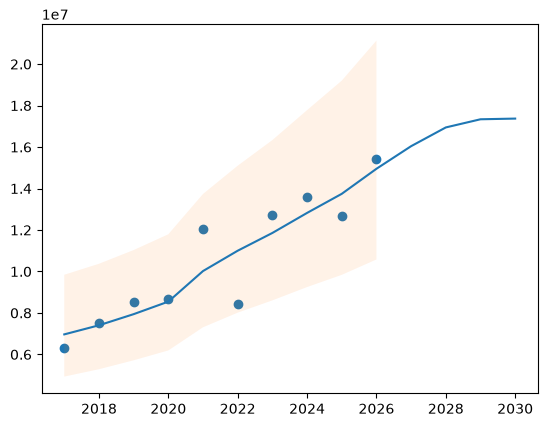

In [51]:
impostos_model.get_plot2(exogs=fc_set)

#### 3.2.2 Contribuições

O grupo de contribuições também é previsto com a forma funcional log-log usando o IPCA como variável exógena, contudo, é usado toda a série disponível.

In [52]:
contribuicoes_model: Model = Model('log(contribuicoes) ~ log(ipca)', is_log=True)

O R2 é de quase 77% e todos os coeficientes foram significativos.

In [53]:
contribuicoes_model.get_summary()

<class 'statsmodels.iolib.summary2.Summary'>
"""
                  Results: Ordinary least squares
===================================================================
Model:              OLS                Adj. R-squared:     0.760   
Dependent Variable: log(contribuicoes) AIC:                -7.9574 
Date:               2026-10-25 20:08   BIC:                -6.8275 
No. Observations:   13                 Log-Likelihood:     5.9787  
Df Model:           1                  F-statistic:        39.05   
Df Residuals:       11                 Prob (F-statistic): 6.27e-05
R-squared:          0.780              Scale:              0.027581
--------------------------------------------------------------------
                Coef.   Std.Err.     t      P>|t|    [0.025   0.975]
--------------------------------------------------------------------
Intercept      12.8820    0.0924  139.3698  0.0000  12.6785  13.0854
log(ipca)       1.4567    0.2331    6.2486  0.0001   0.9436   1.9698
-------------------------------------------------------------------
Omnibus:               0.881         Durbin-Watson:           2.689
Prob(Omnibus):         0.644         Jarque-Bera (JB):        0.614
Skew:                  -0.482        Prob(JB):                0.736
Kurtosis:              2.545         Condition No.:           6    
===================================================================
Notes:
[1] Standard Errors assume that the covariance matrix of the errors
is correctly specified.
"""

O gráfico mostra um bom ajuste dos valores e os valores previstos não mostram incosistências e incoerências.

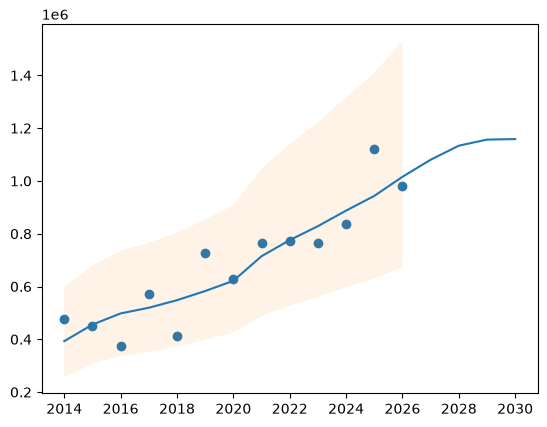

In [54]:
contribuicoes_model.get_plot2(exogs=fc_set)

#### 3.2.3 Receitas patrimoniais

In [ ]:
patrimonial_model: Model = Model('patrimonial ~ selic')

In [56]:
patrimonial_model.get_summary()


<class 'statsmodels.iolib.summary2.Summary'>
"""
                      Results: Ordinary least squares
============================================================================
Model:                 OLS                 Adj. R-squared:        0.570     
Dependent Variable:    patrimonial         AIC:                   389.7736  
Date:                  2026-10-25 20:08    BIC:                   390.9035  
No. Observations:      13                  Log-Likelihood:        -192.89   
Df Model:              1                   F-statistic:           16.89     
Df Residuals:          11                  Prob (F-statistic):    0.00173   
R-squared:             0.606               Scale:                 5.3422e+11
----------------------------------------------------------------------------
             Coef.       Std.Err.     t    P>|t|      [0.025       0.975]   
----------------------------------------------------------------------------
Intercept -988393.8256 636814.1117 -1.5521 0.1489 -2390012.2352  413224.5841
selic     1357402.7617 330314.0516  4.1094 0.0017   630386.4361 2084419.0874
----------------------------------------------------------------------------
Omnibus:                   0.262           Durbin-Watson:              1.160
Prob(Omnibus):             0.877           Jarque-Bera (JB):           0.332
Skew:                      0.265           Prob(JB):                   0.847
Kurtosis:                  2.424           Condition No.:              8    
============================================================================
Notes:
[1] Standard Errors assume that the covariance matrix of the errors is
correctly specified.
"""

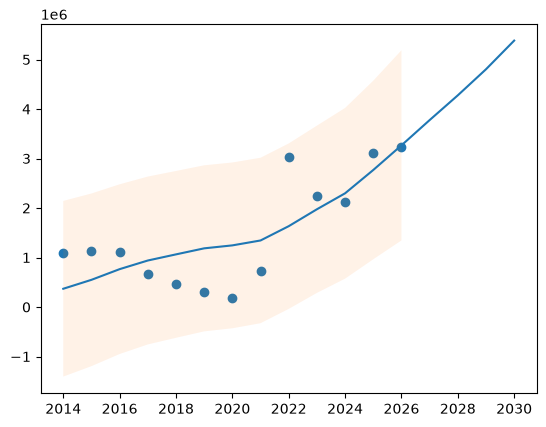

In [57]:
patrimonial_model.get_plot2(exogs=fc_set)

#### 3.2.4 Receitas de Serviços

A receita de serviços mostrou-se basicamente aleatória e possuindo uma quebra estrutural pré e pós 2019. Isto posto, optou-se por utilzar a média da série desde 2019 como previsão.

In [58]:
servicos_model: Model = Model('servicos ~ 1', data=fit_set[fit_set.index >=2019])

In [59]:
servicos_model.get_summary()

<class 'statsmodels.iolib.summary2.Summary'>
"""
                  Results: Ordinary least squares
===================================================================
Model:              OLS              Adj. R-squared:     -0.000    
Dependent Variable: servicos         AIC:                178.7582  
Date:               2026-10-25 20:08 BIC:                178.8377  
No. Observations:   8                Log-Likelihood:     -88.379   
Df Model:           0                F-statistic:        nan       
Df Residuals:       7                Prob (F-statistic): nan       
R-squared:          -0.000           Scale:              2.6373e+08
-------------------------------------------------------------------
             Coef.     Std.Err.   t    P>|t|    [0.025     0.975]  
-------------------------------------------------------------------
Intercept  37190.8487 5741.6208 6.4774 0.0003 23614.0730 50767.6245
-------------------------------------------------------------------
Omnibus:                6.036        Durbin-Watson:           1.617
Prob(Omnibus):          0.049        Jarque-Bera (JB):        1.860
Skew:                   1.150        Prob(JB):                0.395
Kurtosis:               3.539        Condition No.:           1    
===================================================================
Notes:
[1] Standard Errors assume that the covariance matrix of the errors
is correctly specified.
"""

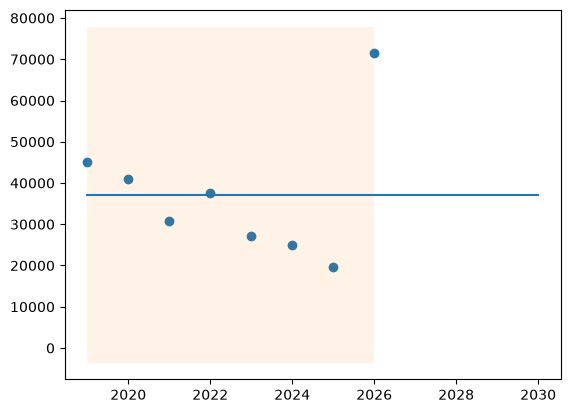

In [60]:
servicos_model.get_plot2(exogs=fc_set)

#### 3.2.5 Transferências constitucionais

Para o grupo de transferências constitucionais, foi utilizada toda a série disponível e, como variáveis independentes, o IPCA e a *dummy* referente à pandemia de COVID-19. A variável IPCA foi logaritimizada.

In [61]:
transferencias_model: Model = Model('log(transferencias) ~ log(ipca)', is_log=True)

Todos os coeficientes foram estatisticamente significativos e o R2 é de 84%,

In [62]:
transferencias_model.get_summary()

<class 'statsmodels.iolib.summary2.Summary'>
"""
                   Results: Ordinary least squares
=====================================================================
Model:              OLS                 Adj. R-squared:     0.921    
Dependent Variable: log(transferencias) AIC:                -24.0095 
Date:               2026-10-25 20:08    BIC:                -22.8796 
No. Observations:   13                  Log-Likelihood:     14.005   
Df Model:           1                   F-statistic:        140.4    
Df Residuals:       11                  Prob (F-statistic): 1.32e-07 
R-squared:          0.927               Scale:              0.0080233
-----------------------------------------------------------------------
              Coef.    Std.Err.      t       P>|t|     [0.025    0.975]
-----------------------------------------------------------------------
Intercept    17.0103     0.0499   341.2139   0.0000   16.9006   17.1200
log(ipca)     1.4901     0.1257    11.8508   0.0000    1.2133    1.7668
---------------------------------------------------------------------
Omnibus:               0.992          Durbin-Watson:            1.343
Prob(Omnibus):         0.609          Jarque-Bera (JB):         0.689
Skew:                  -0.092         Prob(JB):                 0.709
Kurtosis:              1.888          Condition No.:            6    
=====================================================================
Notes:
[1] Standard Errors assume that the covariance matrix of the errors
is correctly specified.
"""

O gráfico mostra um bom ajuste dos valores e os valores previstos não mostram incosistências e incoerências.

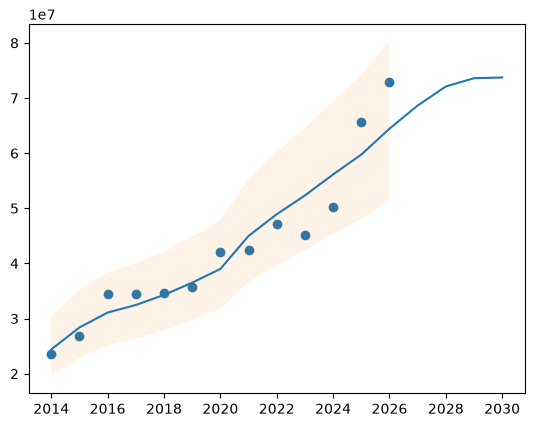

In [63]:
transferencias_model.get_plot2(exogs=fc_set)

#### 3.2.6 Outras receitas

Por fim, para o grupo de Outras Receitas, usou-se a forma funcional log-log, com o IPCA logaritmizado como variável exógena. A série usada para estimar leva em conta os anos de 2019 até 2025.

In [64]:
# Modeling
outras_model: Model = Model(
    'log(outras) ~ log(ipca)', 
    is_log=True, 
    data=fit_set[(fit_set.index >= 2019) & (fit_set.index <= 2025)]
    )

# faltam: limpeza pública, fpm e icms

Se apresentou um modelo com R2 de 86% e todos os coeficientes foram estatisticamente significativos.

In [65]:
outras_model.get_summary()

/home/pianeiro/Documents/work/pmsjn/ldo-2027/.venv/lib64/python3.13/site-packages/statsmodels/regression/linear_model.py:3297: ValueWarning: omni_normtest is not valid with less than 8 observations; 7 samples were given.
  omni, omnipv = omni_normtest(self.wresid)


<class 'statsmodels.iolib.summary2.Summary'>
"""
                 Results: Ordinary least squares
=================================================================
Model:              OLS              Adj. R-squared:     0.701   
Dependent Variable: log(outras)      AIC:                -6.3760 
Date:               2026-10-25 20:08 BIC:                -6.4842 
No. Observations:   7                Log-Likelihood:     5.1880  
Df Model:           1                F-statistic:        15.08   
Df Residuals:       5                Prob (F-statistic): 0.0116  
R-squared:          0.751            Scale:              0.018617
------------------------------------------------------------------
               Coef.   Std.Err.     t     P>|t|    [0.025   0.975]
------------------------------------------------------------------
Intercept     12.9085    0.2091  61.7343  0.0000  12.3710  13.4460
log(ipca)      1.7581    0.4527   3.8839  0.0116   0.5945   2.9217
-----------------------------------------------------------------
Omnibus:               nan          Durbin-Watson:          2.237
Prob(Omnibus):         nan          Jarque-Bera (JB):       0.516
Skew:                  -0.548       Prob(JB):               0.773
Kurtosis:              2.247        Condition No.:          11   
=================================================================
Notes:
[1] Standard Errors assume that the covariance matrix of the
errors is correctly specified.
"""

O gráfico mostra um bom ajuste dos valores e os valores previstos não mostram incosistências e incoerências.

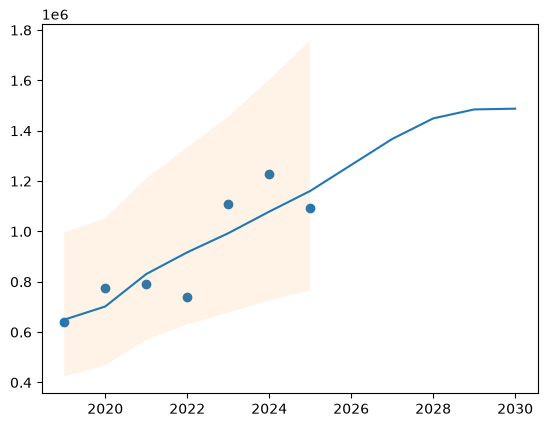

In [66]:
outras_model.get_plot2(exogs=fc_set)

#### 3.2.7 FPM

O FPM foi previsto usando a forma funcional log-log, usando o IPCA e a tendência temporal, e levando em conta toda a série disponível.

In [67]:
fpm_model: Model = Model('log(fpm) ~ log(ipca) + log(trend)', is_log=True)

O R2 foi de quase 97% e todos os coeficientes foram estatisticamente significantes. A *dummy* referente à pandemia de COVID-19 foi testada, mas mostrou-se estatisticamente insignificante, motivo pelo qual foi retirada.

In [68]:
fpm_model.get_summary()

<class 'statsmodels.iolib.summary2.Summary'>
"""
                 Results: Ordinary least squares
==================================================================
Model:              OLS              Adj. R-squared:     0.960    
Dependent Variable: log(fpm)         AIC:                -27.7595 
Date:               2026-10-25 20:08 BIC:                -26.0647 
No. Observations:   13               Log-Likelihood:     16.880   
Df Model:           2                F-statistic:        145.8    
Df Residuals:       10               Prob (F-statistic): 4.00e-08 
R-squared:          0.967            Scale:              0.0056709
-------------------------------------------------------------------
               Coef.   Std.Err.     t      P>|t|    [0.025   0.975]
-------------------------------------------------------------------
Intercept     16.5257    0.0623  265.3644  0.0000  16.3870  16.6645
log(ipca)      2.9512    0.3272    9.0190  0.0000   2.2221   3.6803
log(trend)    -0.3385    0.0879   -3.8503  0.0032  -0.5344  -0.1426
------------------------------------------------------------------
Omnibus:               0.148        Durbin-Watson:           1.359
Prob(Omnibus):         0.928        Jarque-Bera (JB):        0.352
Skew:                  0.123        Prob(JB):                0.839
Kurtosis:              2.233        Condition No.:           35   
==================================================================
Notes:
[1] Standard Errors assume that the covariance matrix of the
errors is correctly specified.
"""

O gráfico mostra um bom ajuste dos valores e os valores previstos não mostram incosistências e incoerências.

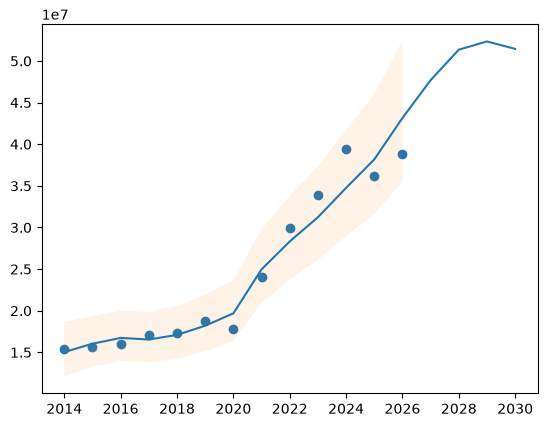

In [69]:
fpm_model.get_plot2(exogs=fc_set)

#### 3.2.8 ICMS

O ICMS foi previsto usando o IPM o IPCA logaritmizado e a *dummy* referente à pandemia de COVID-19 como variáveis exógenas. Foram utilizadas todas as observações da série.

In [70]:
icms_model: Model = Model('icms ~ ipm + covid + log(ipca)')

O R2 alcançou 96% e todos os coeficientes foram estatisticamente significantes.

In [71]:
icms_model.get_summary()

<class 'statsmodels.iolib.summary2.Summary'>
"""
                          Results: Ordinary least squares
===================================================================================
Model:                    OLS                   Adj. R-squared:          0.954     
Dependent Variable:       icms                  AIC:                     418.0066  
Date:                     2026-10-25 20:08      BIC:                     420.2664  
No. Observations:         13                    Log-Likelihood:          -205.00   
Df Model:                 3                     F-statistic:             84.49     
Df Residuals:             9                     Prob (F-statistic):      6.53e-07  
R-squared:                0.966                 Scale:                   4.2114e+12
-----------------------------------------------------------------------------------
              Coef.         Std.Err.      t    P>|t|      [0.025         0.975]    
-----------------------------------------------------------------------------------
Intercept  -7723519.6107  1902761.6464 -4.0591 0.0028 -12027865.4982  -3419173.7232
ipm       126739536.9420 14685963.6985  8.6300 0.0000  93517578.9689 159961494.9150
covid      -5172875.5973  2627478.4868 -1.9688 0.0805 -11116644.8763    770893.6817
log(ipca)   8492188.9034  4425011.5131  1.9191 0.0872  -1517882.5864  18502260.3931
-----------------------------------------------------------------------------------
Omnibus:                    5.734              Durbin-Watson:                 1.867
Prob(Omnibus):              0.057              Jarque-Bera (JB):              2.409
Skew:                       0.688              Prob(JB):                      0.300
Kurtosis:                   4.599              Condition No.:                 29   
===================================================================================
Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly
specified.
"""

O gráfico mostra um bom ajuste dos valores e os valores previstos não mostram incosistências e incoerências.

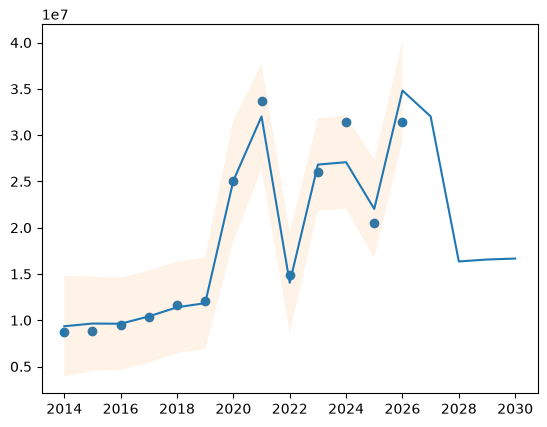

In [72]:
icms_model.get_plot2(exogs=fc_set)

#### 3.2.9 Taxa de limpeza pública

A taxa de limpeza pública foi estimada usando o log do IPCA. A série utilizada começa em 2022, quando a taxa foi estabelecida.

In [73]:
limpeza_model = Model('limpeza_publica ~ log(ipca)', data=fit_set[fit_set.index >= 2022])

Todos os coeficientes foram significantes e o R2 passou de 80%.

In [74]:
limpeza_model.get_summary()

/home/pianeiro/Documents/work/pmsjn/ldo-2027/.venv/lib64/python3.13/site-packages/statsmodels/regression/linear_model.py:3297: ValueWarning: omni_normtest is not valid with less than 8 observations; 5 samples were given.
  omni, omnipv = omni_normtest(self.wresid)


<class 'statsmodels.iolib.summary2.Summary'>
"""
                        Results: Ordinary least squares
===============================================================================
Model:                  OLS                  Adj. R-squared:         0.895     
Dependent Variable:     limpeza_publica      AIC:                    141.9219  
Date:                   2026-10-25 20:08     BIC:                    141.1408  
No. Observations:       5                    Log-Likelihood:         -68.961   
Df Model:               1                    F-statistic:            35.25     
Df Residuals:           3                    Prob (F-statistic):     0.00955   
R-squared:              0.922                Scale:                  9.3136e+10
-------------------------------------------------------------------------------
              Coef.       Std.Err.      t    P>|t|      [0.025        0.975]   
-------------------------------------------------------------------------------
Intercept -5396925.8492 1181548.6352 -4.5677 0.0197 -9157140.9379 -1636710.7606
log(ipca) 12488586.6299 2103448.8364  5.9372 0.0096  5794473.6521 19182699.6078
-------------------------------------------------------------------------------
Omnibus:                   nan               Durbin-Watson:               3.217
Prob(Omnibus):             nan               Jarque-Bera (JB):            0.131
Skew:                      -0.065            Prob(JB):                    0.937
Kurtosis:                  2.218             Condition No.:               20   
===============================================================================
Notes:
[1] Standard Errors assume that the covariance matrix of the errors is
correctly specified.
"""

O gráfico mostra um bom ajuste dos valores e os valores previstos não mostram incosistências e incoerências.

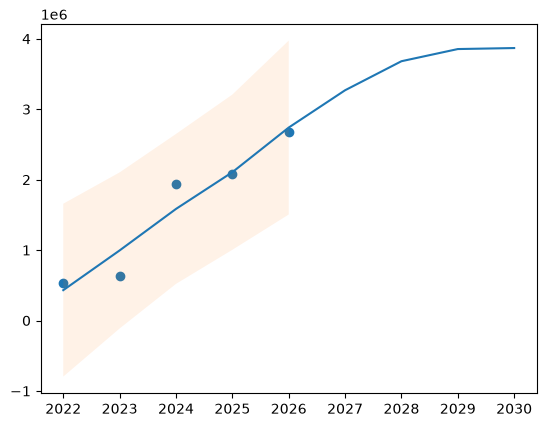

In [75]:
limpeza_model.get_plot2(exogs=fc_set)

#### 3.2.9 Visão geral das previsões de alto nível

A inspeção das previsões de alto nível, quando confrontados com os anos imediatamente anteriores, não permitem identificar nenhuma inconsistência aparente.

In [76]:
tlfc: DataFrame = DataFrame({
    'impostos': impostos_model.predict(fc_set),
    'limpeza_publica': limpeza_model.predict(fc_set),
    'contribuicoes': contribuicoes_model.predict(fc_set),
    'patrimonial': patrimonial_model.predict(fc_set),
    'servicos': servicos_model.predict(fc_set),
    'transferencias': transferencias_model.predict(fc_set),
    'fpm': fpm_model.predict(fc_set),
    'icms': icms_model.predict(fc_set),
    'outras': outras_model.predict(fc_set)
})

In [77]:
overview: DataFrame = concat([revenues.tail(3), tlfc])
overview['total'] = overview.sum(axis=1)

overview.fillna(0).div(1e6).round(1)

,contribuicoes,fpm,icms,impostos,limpeza_publica,outras,patrimonial,servicos,transferencias,total
ANO,,,,,,,,,,
2024,0.8,39.5,31.4,13.6,1.9,1.2,2.1,0.0,50.3,140.9
2025,1.1,36.1,20.5,12.7,2.1,1.1,3.1,0.0,65.6,142.4
2026,1.0,38.8,31.4,15.4,2.7,2.0,3.2,0.1,72.8,167.5
2027,1.1,47.7,32.0,16.0,3.3,1.4,3.8,0.0,68.6,173.9
2028,1.1,51.4,16.3,16.9,3.7,1.4,4.3,0.0,72.1,167.3
2029,1.2,52.3,16.6,17.3,3.9,1.5,4.8,0.0,73.6,171.2
2030,1.2,51.5,16.7,17.4,3.9,1.5,5.4,0.0,73.7,171.1


# 4. Desagregação dos resultados

Obtidas as estimativas de alto nível, a desagregação é realizada obtendo o peso de cada receita dentro de seu grupo, de modo que sua estimativa distribuída será, então, obtida pela estimativa de alto nível multiplicada pelo respectivo peso.

In [78]:
def disaggregates_prediction(
        group_prefix: str, 
        model: Model,
        exception_prefixes: list[str] = [],  
        ref_year: int = 2026, 
        ref_df: DataFrame = raw_revenues
    ) -> DataFrame:

    base: DataFrame = ref_df.loc[
        (ref_df['ANO'] == ref_year)
        & (ref_df['VL_ORCADO'] > 0)
        & (ref_df['NIVEL'] == 'A'),
        ['MES', 'CD_CONTA_SG', 'DS_CONTA_SG', 'VL_ORCADO', 'VL_ARRECADADO']
    ].copy()
    base['VL_PROJETADO'] = base.apply(project_december, axis=1)
    base.drop(columns=['MES', 'VL_ORCADO', 'VL_ARRECADADO'], inplace=True)
    base.columns= ['cod', 'desc', 'value']
    base['cod'] = base['cod'].astype('str')
 
    matrix: DataFrame = base.loc[
        (base['cod'].str.startswith(group_prefix))
        & (~base['cod'].str.startswith(tuple(exception_prefixes)))
    ].copy()
    matrix['ratio'] = matrix['value'] / matrix['value'].sum()
    matrix.set_index(['cod', 'desc'], inplace=True)

    prediction = model.predict(fc_set)

    results: DataFrame = DataFrame()
    for i, v in prediction.items(): results[i] = round(matrix['ratio'] * v / 1e3, 0) * 1e3
    
    return results

In [79]:
impostos_results: DataFrame = disaggregates_prediction(group_prefix='11', exception_prefixes=['1122530'], model=impostos_model)
limpeza_results: DataFrame = disaggregates_prediction(group_prefix='1122530', model=limpeza_model)
contribuicoes_results: DataFrame = disaggregates_prediction(group_prefix='12', model=contribuicoes_model)
patrimonial_results: DataFrame = disaggregates_prediction(group_prefix='13', model=patrimonial_model)
servicos_results: DataFrame = disaggregates_prediction(group_prefix='16', model=servicos_model)
transferencias_results: DataFrame = disaggregates_prediction(group_prefix='17', exception_prefixes=['171151', '17215001'], model=transferencias_model)
fpm_results: DataFrame = disaggregates_prediction(group_prefix='171151', model=fpm_model)
icms_results: DataFrame = disaggregates_prediction(group_prefix='17215001', model=icms_model)
outras_results: DataFrame = disaggregates_prediction(group_prefix=('19'), model=outras_model)

/tmp/ipykernel_1803317/1247588718.py:16: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  base.drop(columns=['MES', 'VL_ORCADO', 'VL_ARRECADADO'], inplace=True)
/tmp/ipykernel_1803317/1247588718.py:25: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  matrix.set_index(['cod', 'desc'], inplace=True)
/tmp/ipykernel_1803317/1247588718.py:16: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  base.drop(columns=['MES', 'VL_ORCADO', 'VL_ARRECADADO'], inplace=True)
/tmp/ipykernel_1803317/12475

In [80]:
results_dataframe: DataFrame = concat([
        impostos_results, limpeza_results, contribuicoes_results, patrimonial_results,
        servicos_results, transferencias_results, fpm_results, icms_results, outras_results
    ])

In [81]:
results_dataframe.to_csv('estimativas.csv')